In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

def Desc_stat(sample, field):
  col_data = sample[field]

  minimum = col_data.min()
  maximum = col_data.max()

  return {
    "Average": col_data.mean(),
    "Median": col_data.median(),
    "Mode": col_data.mode().tolist(),
    "Minimum": minimum,
    "Maximum": maximum,
    "Range": maximum - minimum,
    "Std Dev": col_data.std(),
    "Variance": col_data.var(),
    "Skewness": col_data.skew(),
    "Kurtosis": col_data.kurt(),
    "25th Percentile": col_data.quantile(0.25),
    "75th Percentile": col_data.quantile(0.75),
    "Inter Quartile Range": col_data.quantile(0.75) - col_data.quantile(0.25),
    "Count": col_data.count()
  }

In [14]:
data = pd.read_csv("Advertising.csv")
data = data[["TV", "Radio", "Newspaper", "Sales"]]

sample_size = 150
sample = data.sample(n=sample_size, replace=False, random_state=42)

random_statistics = Desc_stat(sample, "Sales")
print(pd.Series(random_statistics))

Average                 13.981333
Median                      12.85
Mode                       [11.7]
Minimum                       3.2
Maximum                      25.5
Range                        22.3
Std Dev                  5.174958
Variance                26.780186
Skewness                 0.430054
Kurtosis                -0.601298
25th Percentile            10.325
75th Percentile              17.4
Inter Quartile Range        7.075
Count                         150
dtype: object


In [15]:
step = 2
start = int(np.random.default_rng(42).integers(0, step))

systematic_sample = data.iloc[start::step]
systematic_statistics = Desc_stat(systematic_sample, "Sales")

print(pd.Series(systematic_statistics))

Average                      13.354
Median                        11.85
Mode                    [9.5, 11.8]
Minimum                         1.6
Maximum                        25.5
Range                          23.9
Std Dev                    5.295232
Variance                  28.039479
Skewness                   0.415935
Kurtosis                  -0.404971
25th Percentile               9.575
75th Percentile              17.025
Inter Quartile Range           7.45
Count                           100
dtype: object


In [9]:
report = pd.DataFrame({
    "Full dataset": Desc_stat(data, "Sales"),
    "Random sample": random_statistics,
    "Systematic sample": systematic_statistics
})
print(report)

                     Full dataset Random sample Systematic sample
Average                   14.0225     13.981333            13.354
Median                       12.9         12.85             11.85
Mode                        [9.7]        [11.7]       [9.5, 11.8]
Minimum                       1.6           3.2               1.6
Maximum                      27.0          25.5              25.5
Range                        25.4          22.3              23.9
Std Dev                  5.217457      5.174958          5.295232
Variance                27.221853     26.780186         28.039479
Skewness                 0.407571      0.430054          0.415935
Kurtosis                -0.408869     -0.601298         -0.404971
25th Percentile            10.375        10.325             9.575
75th Percentile              17.4          17.4            17.025
Inter Quartile Range        7.025         7.075              7.45
Count                         200           150               100


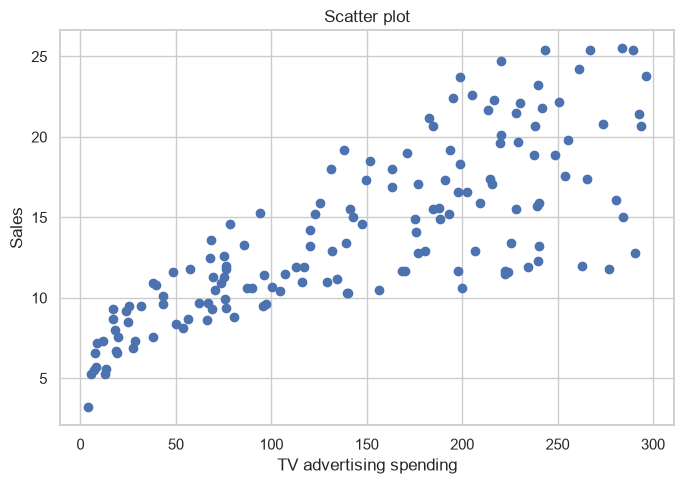

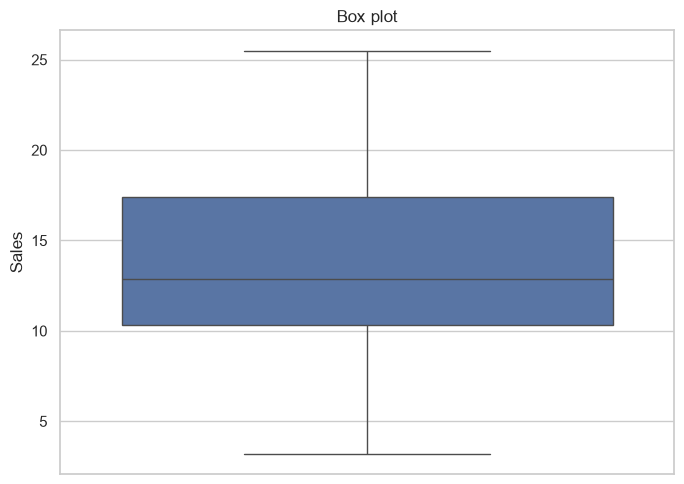

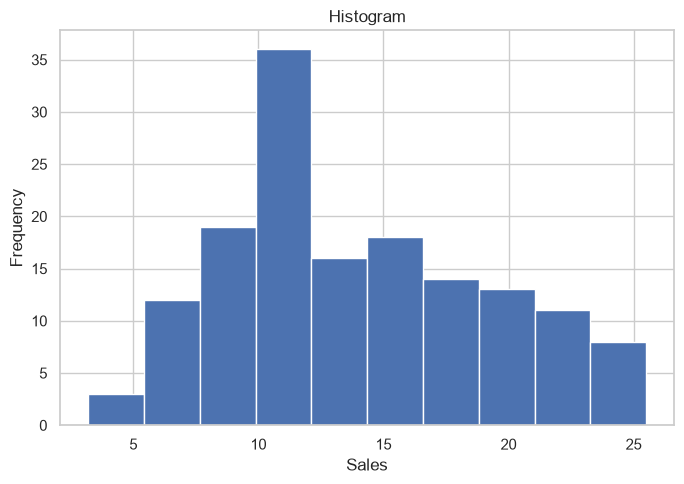

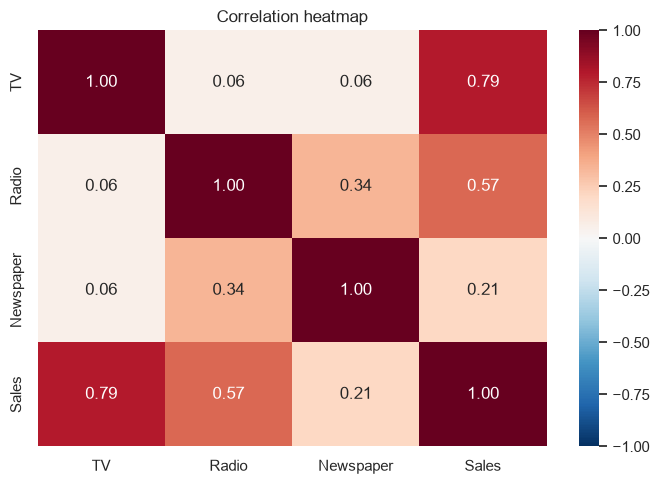

In [16]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))
plt.scatter(sample["TV"], sample["Sales"])
plt.title("Scatter plot")
plt.xlabel("TV advertising spending")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.boxplot(y=sample["Sales"])
plt.title("Box plot")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(sample["Sales"], bins=10, edgecolor="white")
plt.title("Histogram")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(
    sample.corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

In [17]:
pearson_r, pearson_p = stats.pearsonr(
    sample["TV"], sample["Sales"]
)
spearman_r, spearman_p = stats.spearmanr(
    sample["TV"], sample["Sales"]
)

print("Pearson:", pearson_r, pearson_p)
print("Spearman:", spearman_r, spearman_p)

Pearson: 0.7905424460144423 2.5026359357998526e-33
Spearman: 0.814873391166627 7.093420644135545e-37


In [12]:
population_mean = data["Sales"].mean()

# Check normality
shapiro_w, shapiro_p = stats.shapiro(sample["Sales"])

# Compare the sample mean with the reference mean
t_statistic, t_p = stats.ttest_1samp(
    sample["Sales"], popmean=population_mean
)

print("Reference mean:", population_mean)
print("Sample mean:", sample["Sales"].mean())
print("Shapiro-Wilk:", shapiro_w, shapiro_p)
print("T-test:", t_statistic, t_p)
print("Degrees of freedom:", len(sample) - 1)

Reference mean: 14.0225
Sample mean: 13.981333333333332
Shapiro-Wilk: 0.9662454233654748 0.0009631899863173622
T-test: -0.09742816811185892 0.9225173095472987
Degrees of freedom: 149
